# 1. Abstract 

This notebook presents a pedagogical study of Vaswani et al.'s *Attention Is All You Need*. It explains the Transformer architecture, re-implements its main components in PyTorch, and demonstrates the model on the Multi30K English-German translation task using BPE tokenization. The reproduced system is evaluated with BLEU, achieving a score of 31.8 on the test set. Overall, the project shows how self-attention, multi-head attention, positional encoding, and encoder-decoder masking work together to make the Transformer effective for neural machine translation.

# 2. Introduction

The goal of this notebook is to explain the Transformer as a Track 2 paper presentation: not only what the paper proposed, but why the proposal mattered and how its core mechanisms operate.

The guiding questions are:

- How can attention replace recurrence in sequence-to-sequence modeling?
- What roles do scaled dot-product attention, multi-head attention, positional encoding, masking, residual connections, and feed-forward layers play in the architecture?
- Can a compact PyTorch implementation reproduce the main behavior of the original model on a real translation dataset?

To answer these questions, the notebook first explains the model theory, then builds the main Transformer components step by step, trains the model on Multi30K English-German translation data, and analyzes the resulting translations. The main contributions are a clear walkthrough of the paper, visual explanations of important mechanisms, a runnable implementation, and an experimental discussion of the model's strengths and limitations.

# 3. Prior & Related Work

The Transformer is part of a line of work on neural machine translation. Earlier sequence-to-sequence models, such as Sutskever et al. (2014), used recurrent encoder-decoder architectures to map a source sentence into a target sentence. Bahdanau, Cho, and Bengio (2014) improved this setup with attention, allowing the decoder to look back at relevant source positions instead of relying only on a fixed-length sentence representation.

Other work explored ways to reduce the cost of sequential recurrence. For example, convolutional sequence-to-sequence models such as Gehring et al. (2017) processed tokens with more parallel computation than RNNs, but still relied on stacked convolutional layers to connect distant positions.

Vaswani et al. (2017) differ from these approaches by making self-attention the central operation in both the encoder and decoder. Instead of using recurrence or convolution as the main sequence-processing mechanism, the Transformer connects all token positions directly through attention, while positional encodings provide order information. This notebook uses the related work mainly as context, then focuses on explaining and demonstrating the Transformer itself.

# 4. Transformer Model Theory

## 4.1 Problem Statement and Motivation

Machine Translation requires a model to understand relationships between words that may be far apart in a sentence. Traditional sequence models, such as Recurrent Neural Networks (RNNs) and Long Short-Term Memory (LSTM) networks, process tokens one at a time. This sequential computation limits parallelization and makes learning long-range dependencies more difficult.

The Transformer was proposed to overcome these limitations by replacing recurrence with the attention mechanism. Instead of processing tokens sequentially, it processes the entire sequence in parallel while allowing each token to attend to every other token. This results in faster training and improved translation quality.

The main advantages of the Transformer are:

- Parallel processing of input sequences.
- Better modeling of long-range dependencies.
- Improved translation quality through self-attention.
- Efficient utilization of modern GPU hardware.

The computational complexity of processing a sequence of length $n$ is:

- **RNN/LSTM:** Sequential computation with complexity approximately
  $$
  O(n)
  $$
  since tokens must be processed one after another.

- **Transformer:** Parallel computation where all tokens are processed simultaneously using self-attention, enabling efficient GPU execution despite the attention computation having complexity
  $$
  O(n^2)
  $$
  with respect to the sequence length.

Although self-attention has quadratic complexity, its parallel execution makes the Transformer significantly faster to train than recurrent models in practice.

**Summary**

The Transformer replaces sequential recurrence with self-attention, enabling parallel computation and more effective modeling of contextual relationships between words. This innovation has made it the foundation of modern neural machine translation and large language models.

## 4.2 Transformer Architecture Overview

The Transformer is an encoder-decoder architecture designed for sequence-to-sequence tasks such as machine translation, text summarization, and text generation. Unlike recurrent architectures, the Transformer processes all tokens in parallel, enabling efficient training and better scalability for long sequences.

The architecture is composed of two main components:

- **Encoder:** Responsible for understanding and encoding the input sequence.
- **Decoder:** Responsible for generating the output sequence based on the information provided by the encoder.

The encoder and decoder are both implemented as stacks of 6 identical layers. Together, they transform an input sequence into an output sequence by first extracting contextual information from the source input and then using this information to generate the target output.

### Overall Workflow

The overall processing pipeline is shown in the figure below.

![Transformer Architecutre](images/transformer_architecture.webp)

The input sequence is first converted into numerical representations and processed by the encoder stack. The resulting encoded representations capture information about the entire input sequence and are passed to the decoder. The decoder then uses these representations to generate the output sequence one token at a time until the complete output is produced.

## 4.3 Encoder

The encoder is responsible for processing the input sequence and transforming it into a set of contextual representations that capture the meaning of the entire sequence. It serves as the information extraction of the Transformer and provides the decoder with a rich representation of the source input.

The encoder consists of a stack of six identical layers. Each layer receives the output of the previous layer and progressively refines the representation of the input tokens. Through this hierarchical processing, information from different parts of the sequence is integrated, allowing each token representation to become aware of its surrounding context.

The encoder receives:

- Input token embeddings
- Positional encodings

and produces:

- Contextualized representations of all input tokens

Each encoder layer contains the following components:

1. Multi-Head Self-Attention
2. Add & Normalize
3. Feed Forward Network
4. Add & Normalize

These components are applied sequentially within every encoder layer.

### Structure of a Single Encoder Layer

The encoder layer is shown in the figure below.

![Encoder Architecutre](images/encoder_architecture.png)

The input token embeddings are combined with positional encodings and passed to the first encoder layer. Each encoder layer applies multi-head self-attention to capture relationships between tokens, followed by a feed forward network to further refine the representations. Residual connections and layer normalization are applied after each sublayer.

The output of one encoder layer becomes the input to the next, and this process is repeated across all six encoder layers. As the data moves through the stack, the token representations become increasingly context-aware by incorporating information from the entire sequence.

The final encoder output acts as a contextual memory of the source sequence and provides the decoder with the information required to generate the target sequence.

## 4.4 Decoder

The decoder is responsible for generating the output sequence based on the information produced by the encoder. Unlike the encoder, which processes the entire input sequence simultaneously, the decoder generates the output one token at a time.

The decoder consists of a stack of six identical layers. During generation, it receives both the encoder representations and the tokens that have already been generated. Using this information, it predicts the most probable next token in the sequence.

The decoder receives:

- Previously generated output tokens
- Positional encodings
- Encoder representations

and produces:

- Probability distribution over the vocabulary for the next token

Each decoder layer contains the following components:

1. Masked Multi-Head Self-Attention
2. Add & Normalize
3. Encoder-Decoder Attention
4. Add & Normalize
5. Feed Forward Network
6. Add & Normalize

These components are applied sequentially within every decoder layer.

### Structure of a Single Decoder Layer

The decoder layer is shown in the figure below.

![Deoder Architecutre](images/decoder_architecture.png)

The decoder receives the target token embeddings, combined with positional encodings, as well as the encoder outputs. The input first passes through masked multi-head self-attention, which allows each token to attend only to previously generated tokens while preventing access to future tokens.

The resulting representations are then processed by encoder-decoder attention, where the decoder attends to the contextual representations produced by the encoder. This enables the decoder to incorporate information from the source sequence when generating the output.

Next, the representations pass through a feed forward network to further refine the extracted information. Residual connections and layer normalization are applied after each sublayer.

The output of one decoder layer becomes the input to the next, and this process is repeated across all six decoder layers. The final decoder output is then passed through a linear layer and a softmax function to produce a probability distribution over the target vocabulary, from which the next token is predicted.

### Output Generation Process

During training, the decoder receives the target sequence shifted by one position so that it learns to predict the next token at every step.

During inference, generation starts with a special start-of-sequence token. The decoder predicts one token at a time, appends the predicted token to the generated sequence, and repeats the process until an end-of-sequence token is produced.

The decoder therefore acts as the sequence generation component of the Transformer, converting the contextual information extracted by the encoder into the final output sequence.


## 4.5 Attention Mechanism

Attention is the mechanism that enables the Transformer to model relationships between tokens in a sequence. Instead of processing tokens one at a time, attention allows each token to examine other relevant tokens and gather information from them.

The attention mechanism operates using three vector representations:

- **Query (Q):** represents the information that a token is looking for.
- **Key (K):** represents the information that a token can offer.
- **Value (V):** contains the actual information associated with the token.

For a given token, its Query is compared with the Keys of all other tokens to determine which tokens are most relevant. The resulting relevance scores are then used to combine the corresponding Value vectors and produce a context-aware representation.

In the encoder, self-attention allows every token to attend to all other tokens in the input sequence. In the decoder, attention is used to attend to previously generated tokens.

This mechanism enables the Transformer to capture long-range dependencies and contextual relationships without relying on recurrent or convolutional structures.

## 4.6 Scaled Dot-Product Attention

Scaled Dot-Product Attention is the mechanism used in the Transformer to compute the relevance between tokens. Given the Query (Q), Key (K), and Value (V) representations introduced in the previous section, attention scores are calculated by comparing each query with all keys using the dot product.

The attention operation is defined as:

$$
\text{Attention}(Q,K,V) = 

\text{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)
V
$$

where:

* (Q) is the matrix of query vectors.
* (K) is the matrix of key vectors.
* (V) is the matrix of value vectors.
* (d_k) is the dimensionality of the key vectors.

The computation consists of four steps:

**1. Compute Query-Key Similarity**

The dot product between queries and keys is calculated:

$$
QK^T
$$

This produces an attention score matrix that measures how strongly each token is related to every other token in the sequence.

**2. Apply Scaling**

The attention scores are scaled by the square root of the key dimension:

$$
\frac{QK^T}{\sqrt{d_k}}
$$

This scaling prevents the dot-product values from becoming excessively large when the vector dimensionality increases.

**3. Convert Scores to Attention Weights**

The Softmax function is applied to normalize the scores into a probability distribution:

$$
\text{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)
$$

The resulting attention weights indicate the importance of each token relative to the current token.

**4. Compute the Weighted Sum**

The attention weights are multiplied by the value matrix (V):

$$
\text{Attention Weights} \times V
$$

This produces a context-aware representation that combines information from the most relevant tokens.

The scaling factor $(\sqrt{d_k})$ is important because the magnitude of dot products grows as the dimensionality increases. Large values can push the Softmax function into regions with very small gradients, making optimization difficult. Dividing by $(\sqrt{d_k})$ keeps the values within a suitable range and improves training stability.

Figure below illustrates the computation performed by Scaled Dot-Product Attention.

![Scaled Dot-Product Attention](images/q_k_v.png)

Figure below compares encoder self-attention and decoder masked self-attention. In the encoder, each token can attend to all tokens in the sequence. In the decoder, future positions are masked to ensure that predictions depend only on previously generated tokens.

![Encoder and Decoder Attention Matrices](images/encoder_decoder_matrix.png)

The attention mechanism described above corresponds to a single attention head. In practice, the Transformer employs multiple attention heads operating in parallel, which is discussed in the next section.

## 4.7 Multi-Head Attention

The Transformer extends the attention mechanism by using **multiple attention heads** instead of a single one. Each head independently computes attention using its own learned matrices for the queries ($Q$), keys ($K$), and values ($V$). This allows the model to capture different types of relationships between words simultaneously.

For each attention head, the Scaled Dot-Product Attention is computed as

$$
\text{head}_i = \text{Attention}(QW_i^Q,\; KW_i^K,\; VW_i^V),
$$

where $W_i^Q$, $W_i^K$, and $W_i^V$ are the learned projection matrices for the $i$-th head.

The outputs of all attention heads are then concatenated and projected back to the model dimension:

$$
\text{MultiHead}(Q,K,V) = \text{Concat}(\text{head}_1,\ldots,\text{head}_h)W^O,
$$

where:
- $h$ is the number of attention heads.
- $W^O$ is the output projection matrix.

Using multiple heads enables the model to learn different contextual patterns at the same time. For example, one head may focus on grammatical relationships, while another captures semantic similarities or long-range dependencies.

**Multi-Head Attention Architecture**

![Multi-Head Attention](images/multi_head_attention.png)

**Key Points**

- The input is projected into multiple sets of queries, keys, and values.
- Each attention head learns different relationships independently.
- The outputs of all heads are concatenated.
- A final linear layer combines the information into a single representation.

## 4.8 Positional Encoding

### 4.8.1 Why Do Transformers Need Position?

Transformers do not read tokens one by one like RNNs. Instead, self-attention looks at all tokens in parallel. This is efficient, but it means the model does not automatically know the order of the tokens.

![Positional Encoding](images/no_positional_encoding_problem.png)

So, if the model only receives token embeddings, it knows what the words are, but not where they appear. Positional encoding solves this by adding position information to each token before it enters the Transformer.

### 4.8.2 Adding Position to Token Meaning

Each token is first converted into an embedding vector that represents its meaning. To add order information, the Transformer adds a positional encoding vector to it:

$$
\text{Input}*{pos} = \text{Embedding}(x*{pos}) + PE_{pos}
$$

Here, $\text{Embedding}(x_{pos})$ represents what the token is, while $PE_{pos}$ represents where it appears in the sequence.

![Graph Positional Encoding](images/positional_encoding_on_graph.png)

As shown in the figure, adding positional encoding changes the token’s final vector, allowing the model to use both meaning and position before the attention layers.

### 4.8.3 Sinusoidal Positional Encoding

In the original Transformer, positional encodings are fixed sinusoidal vectors. This means they are generated using sine and cosine functions, instead of being learned during training.

For each position $pos$ and dimension index $i$, the encoding is defined as:

$$
PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i / d_{model}}}\right)
$$

$$
PE(pos, 2i + 1) = \cos\left(\frac{pos}{10000^{2i / d_{model}}}\right)
$$

Even dimensions use sine, while odd dimensions use cosine. As shown in the heatmap, each position gets a different pattern across the embedding dimensions.

![Sinusoidal Heatmap](images/sinusoidal.webp)

### 4.8.4 Why Are Sinusoids Useful?

Sinusoidal encodings are useful because they create smooth and structured position patterns. Nearby positions have related encodings, while farther positions become more different.

Another important property is that relative distances can be represented consistently. For example, the relationship between position $pos$ and position $pos + k$ follows a predictable pattern for any fixed offset $k$. This helps the model learn not only where a token is, but also how far it is from other tokens.

The authors also tested learned positional embeddings and found similar results. However, they chose sinusoidal encodings because they may generalize better to sequence lengths longer than those seen during training.

### 4.8.5 Summary

Positional encoding is what gives the Transformer a sense of order. Token embeddings tell the model what the tokens are, while positional encodings tell it where the tokens appear. By adding both vectors together, the attention layers can use meaning and position at the same time.

## 4.9 Feed Forward Network

After the Multi-Head Attention layer, each token representation is independently passed through a fully connected feed-forward network (FFN). The same network and parameters are applied to every position in the sequence, which is why it is called **position-wise**.

The FFN consists of two linear transformations with a ReLU activation function between them:

$$
\text{FFN}(x) = \max(0, xW_1 + b_1)W_2 + b_2,
$$

where:

- $W_1 \in \mathbb{R}^{d_{\text{model}} \times d_{\text{ff}}}$
- $W_2 \in \mathbb{R}^{d_{\text{ff}} \times d_{\text{model}}}$

In the original Transformer paper,

$$
d_{\text{ff}} = 4 \times d_{\text{model}},
$$

which expands the feature dimension before projecting it back to the original model dimension.

**Key Points**

- Consists of two fully connected (linear) layers.
- Uses a ReLU activation between the two layers.
- Applied independently to every token in the sequence.
- Expands the representation to a higher-dimensional space and then projects it back to the model dimension.
- Helps the model learn more complex nonlinear feature representations.

## 4.10 Residual Connections and Layer Normalization

Each sublayer in the Transformer (Multi-Head Attention and Feed Forward Network) is followed by a **Residual Connection** and **Layer Normalization**, commonly referred to as the **Add & Norm** block.

A residual connection adds the original input of the sublayer to its output, allowing information to flow directly through the network. This helps preserve important features and improves gradient propagation, making it easier to train deep Transformer models.

After the residual addition, Layer Normalization is applied to stabilize the activations and accelerate training by normalizing the feature values of each token.

The output of the Add & Norm block is computed as

$$
\mathrm{Output} = \mathrm{LayerNorm}(x + \mathrm{Sublayer}(x)),
$$

where:

- $x$ is the input to the sublayer.
- $\mathrm{Sublayer}(x)$ is either the Multi-Head Attention or the Feed Forward Network.
- $\mathrm{LayerNorm}(\cdot)$ performs normalization over the feature dimension.

**Dropout in Add & Norm**

- During training, dropout randomly sets part of $\mathrm{Sublayer}(x)$ to zero and scales the remaining values.
- It is applied before the residual addition: $x + \mathrm{Dropout}(\mathrm{Sublayer}(x))$.
- This helps reduce overfitting. During evaluation or inference, dropout is disabled.

So, during training, the Add & Norm computation becomes:

$$
\mathrm{Output} =
\mathrm{LayerNorm}\left(
x + \mathrm{Dropout}(\mathrm{Sublayer}(x))
\right).
$$

**Key Points**

- Residual connections improve gradient flow and enable deep Transformer architectures.
- Layer Normalization stabilizes the activations of each token.
- Dropout is applied before the residual addition to reduce overfitting.
- Every encoder and decoder layer contains two or more Add & Norm blocks surrounding the main sublayers.

# 5. Re-Implementation

## 5.1 Implementation Flow

The Transformer implementation is built step by step from lower-level components to the complete model.

In [1]:
import math

import torch
import torch.nn as nn
import copy
import numpy as np
import random

import csv

In [2]:
# before starting, we will fix the seed for everything for reproducability

SEED = 42

def fixed_seed():

    # Python
    random.seed(SEED)

    # NumPy
    np.random.seed(SEED)

    # PyTorch CPU
    torch.manual_seed(SEED)

    # PyTorch GPU
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    # Deterministic behavior
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    torch.use_deterministic_algorithms(False)

fixed_seed()

## 5.2 Embedding

### 5.2.1 Code

In [3]:
class Embedding(nn.Module):

    def __init__(self, vocab_size, model_dimension):
        super().__init__()

        # Learnable lookup table that maps each token ID
        # to a dense vector representation of size model_dimension.
        self.embeddings_table = nn.Embedding(vocab_size, model_dimension)

        self.model_dimension = model_dimension

    def forward(self, token_ids_batch):

        # Expected input shape:
        # (batch_size, sequence_length)
        assert token_ids_batch.ndim == 2, \
            f'Expected: (batch size, max token sequence length), got {token_ids_batch.shape}'

        # Convert token IDs into embedding vectors.
        # Shape: (B, S) → (B, S, D)
        # B = batch size
        # S = sequence length
        # D = model dimension
        embeddings = self.embeddings_table(token_ids_batch)

        # Scale embeddings by sqrt(model_dimension),
        return embeddings * math.sqrt(self.model_dimension)

### 5.2.2 Result

In [4]:
# Test the Embedding layer with a small batch of token IDs

vocab_size = 11
model_dimension = 512
batch_size = 3
sequence_length = 2

embedding_layer = Embedding(vocab_size, model_dimension)

token_ids_batch = torch.randint(1, 10, size=(batch_size, sequence_length))

embedding_output = embedding_layer(token_ids_batch)

print("Token IDs:")
print(token_ids_batch)

print("\nInput token IDs shape:")
print(token_ids_batch.shape)

print("\nEmbedding output shape:")
print(embedding_output.shape)

print("\nFirst token embedding vector shape:")
print(embedding_output[0, 0].shape)

print("\nFirst 10 values of the first token embedding:")
print(embedding_output[0, 0, :10].detach())

Token IDs:
tensor([[1, 2],
        [3, 3],
        [7, 7]])

Input token IDs shape:
torch.Size([3, 2])

Embedding output shape:
torch.Size([3, 2, 512])

First token embedding vector shape:
torch.Size([512])

First 10 values of the first token embedding:
tensor([-30.8586,   4.3661, -13.8103,   3.6936,  34.1713,   4.8039, -16.4094,
        -21.5588,  11.8046, -10.4961])


### The output shape (3, 2, 512) verifies that each input token was successfully converted into a 512-dimensional embedding vector, as required by the Transformer architecture.

## 5.3 Positional Encoding

### 5.3.1 Code

In [5]:
class PositionalEncoding(nn.Module):

    def __init__(self, model_dimension, dropout_probability, expected_max_sequence_length=5000):
        super().__init__()

        self.dropout = nn.Dropout(p=dropout_probability)

        # Generate sinusoidal positional encodings as described
        # in the original Transformer paper.
        position_id = torch.arange(0, expected_max_sequence_length).unsqueeze(1)
        frequencies = torch.pow(
            10000.,
            -torch.arange(0, model_dimension, 2, dtype=torch.float) / model_dimension
        )

        # Build the positional encoding table.
        positional_encodings_table = torch.zeros(
            expected_max_sequence_length,
            model_dimension
        )

        # Apply sine to even dimensions.
        positional_encodings_table[:, 0::2] = torch.sin(position_id * frequencies)

        # Apply cosine to odd dimensions.
        positional_encodings_table[:, 1::2] = torch.cos(position_id * frequencies)

        # Store positional encodings as a non-trainable buffer.
        self.register_buffer(
            'positional_encodings_table',
            positional_encodings_table
        )

    def forward(self, embeddings_batch):

        # Expected input shape:
        # (batch_size, sequence_length, model_dimension)
        assert embeddings_batch.ndim == 3 and \
               embeddings_batch.shape[-1] == self.positional_encodings_table.shape[1], \
               f'Expected (batch size, max token sequence length, model dimension) got {embeddings_batch.shape}'

        # Select positional encodings matching the input sequence length.
        positional_encodings = self.positional_encodings_table[
            :embeddings_batch.shape[1]
        ]

        # Add positional information to token embeddings
        # and apply dropout.
        return self.dropout(
            embeddings_batch + positional_encodings
        )

### 5.3.2 Result

In [6]:
model_dimension = 512
dropout_probability = 0.1
sequence_length = 10

positional_encoding = PositionalEncoding(
    model_dimension,
    dropout_probability
)

dummy_embeddings = torch.zeros((1, sequence_length, model_dimension))

output = positional_encoding(dummy_embeddings)

print("Input shape:", dummy_embeddings.shape)
print("Output shape:", output.shape)

print("\nPosition 0 (first 10 values):")
print(output[0, 0, :10].detach())

print("\nPosition 1 (first 10 values):")
print(output[0, 1, :10].detach())

Input shape: torch.Size([1, 10, 512])
Output shape: torch.Size([1, 10, 512])

Position 0 (first 10 values):
tensor([0.0000, 1.1111, 0.0000, 1.1111, 0.0000, 0.0000, 0.0000, 1.1111, 0.0000,
        1.1111])

Position 1 (first 10 values):
tensor([0.9350, 0.6003, 0.9132, 0.6330, 0.8911, 0.6638, 0.8688, 0.6927, 0.8464,
        0.7199])


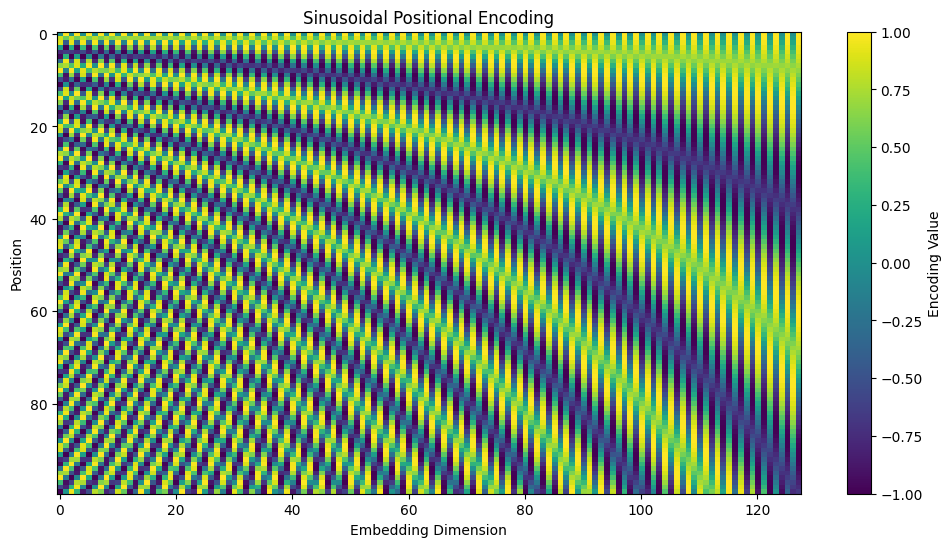

In [7]:
import matplotlib.pyplot as plt

model_dimension = 512
dropout_probability = 0.0
sequence_length = 100

positional_encoding = PositionalEncoding(
    model_dimension,
    dropout_probability,
    expected_max_sequence_length=sequence_length
)

pe_table = positional_encoding.positional_encodings_table.detach()

plt.figure(figsize=(12, 6))
plt.imshow(pe_table[:, :128], aspect="auto")
plt.xlabel("Embedding Dimension")
plt.ylabel("Position")
plt.title("Sinusoidal Positional Encoding")
plt.colorbar(label="Encoding Value")
plt.show()

### Each position generates a distinct sinusoidal pattern, as shown by the changing colors in the heatmap. This enables the Transformer to distinguish between tokens appearing at different positions in the sequence.

## 5.4 Scaled Dot-Product Attention

### 5.4.1 Code

In [8]:
def attention(query, key, value, mask=None, dropout=None):
    # d_k is the size of each key/query vector.
    # It is used to scale the attention scores.
    d_k = query.shape[-1]

    # Compute similarity scores between Query and Key.
    # Shape: (B, H, S, d_k) x (B, H, d_k, S) → (B, H, S, S)
    scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)

    # If a mask is provided, hide unwanted positions
    # by giving them a very large negative score.
    if mask is not None:
        scores = scores.masked_fill(mask == False, float("-inf"))

    # Convert scores into attention probabilities.
    # Each row sums approximately to 1.
    attention_weights = torch.softmax(scores, dim=-1)

    # Apply dropout if provided.
    if dropout is not None:
        attention_weights = dropout(attention_weights)

    # Use attention weights to combine the Value vectors.
    # Shape: (B, H, S, S) x (B, H, S, d_k) → (B, H, S, d_k)
    output = torch.matmul(attention_weights, value)

    return output, attention_weights

### 5.4.2 Result

Query shape: torch.Size([1, 1, 10, 64])
Key shape: torch.Size([1, 1, 10, 64])
Value shape: torch.Size([1, 1, 10, 64])
Attention weights shape: torch.Size([1, 1, 10, 10])
Attention output shape: torch.Size([1, 1, 10, 64])


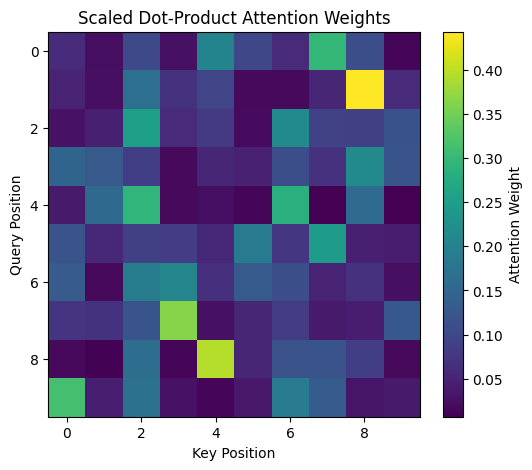

In [9]:
import matplotlib.pyplot as plt

batch_size = 1
num_heads = 1
sequence_length = 10
head_dimension = 64

query = torch.randn(batch_size, num_heads, sequence_length, head_dimension)
key = torch.randn(batch_size, num_heads, sequence_length, head_dimension)
value = torch.randn(batch_size, num_heads, sequence_length, head_dimension)

attention_output, attention_weights = attention(query, key, value)

print("Query shape:", query.shape)
print("Key shape:", key.shape)
print("Value shape:", value.shape)
print("Attention weights shape:", attention_weights.shape)
print("Attention output shape:", attention_output.shape)

plt.figure(figsize=(6, 5))
plt.imshow(attention_weights[0, 0].detach(), aspect="auto")
plt.colorbar(label="Attention Weight")
plt.xlabel("Key Position")
plt.ylabel("Query Position")
plt.title("Scaled Dot-Product Attention Weights")
plt.show()

### The heatmap visualizes the attention weights produced by the Scaled Dot-Product Attention mechanism. Each row represents a query token, while each column represents a key token. The color intensity indicates the attention weight assigned by a query token to a key token, where brighter colors correspond to higher attention scores and darker colors correspond to lower attention scores.

### For example, the bright cell at row 4 and column 6 indicates that the token at query position 4 places significant attention on the token at key position 6. Since the input vectors in this demonstration were randomly generated, the attention pattern appears irregular. However, in a trained Transformer model, these patterns become meaningful and often highlight important relationships between words in a sentence.

## 5.5 Multi-Head Attention

### 5.5.1 Code

In [10]:
def get_clones(module, num_of_deep_copies):
    return nn.ModuleList([copy.deepcopy(module) for _ in range(num_of_deep_copies)])
    
class MultiHeadedAttention(nn.Module):

    def __init__(self, model_dimension, number_of_heads, dropout_probability, log_attention_weights):
        super().__init__()

        # The model dimension must be split evenly across all attention heads.
        assert model_dimension % number_of_heads == 0, \
            f'Model dimension must be divisible by the number of heads.'

        self.head_dimension = int(model_dimension / number_of_heads)
        self.number_of_heads = number_of_heads

        # Three separate linear layers are used to generate Q, K, and V.
        self.qkv_nets = get_clones(nn.Linear(model_dimension, model_dimension), 3)

        # Final projection after concatenating all attention heads.
        self.out_projection_net = nn.Linear(model_dimension, model_dimension)

        self.attention_dropout = nn.Dropout(p=dropout_probability)
        self.softmax = nn.Softmax(dim=-1)

        # Used only when we want to visualize attention weights.
        self.log_attention_weights = log_attention_weights
        self.attention_weights = None

    def attention(self, query, key, value, mask):
        # Compute scaled dot-product attention scores.
        # Shape: (B, NH, S/T, HD) x (B, NH, HD, S/T) → attention score matrix.
        scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(self.head_dimension)

        # Mask unwanted positions so their attention probability becomes zero after softmax.
        if mask is not None:
            scores.masked_fill_(mask == torch.tensor(False), float("-inf"))

        # Convert scores into attention probabilities.
        attention_weights = self.softmax(scores)

        # Apply dropout to attention weights.
        attention_weights = self.attention_dropout(attention_weights)

        # Use attention weights to combine the value vectors.
        intermediate_token_representations = torch.matmul(attention_weights, value)

        return intermediate_token_representations, attention_weights

    def forward(self, query, key, value, mask):
        batch_size = query.shape[0]

        # Project inputs into Q, K, and V, then split them into multiple heads.
        # Shape: (B, S/T, D) → (B, NH, S/T, HD)
        query, key, value = [
            net(x)
            .view(batch_size, -1, self.number_of_heads, self.head_dimension)
            .transpose(1, 2)
            for net, x in zip(self.qkv_nets, (query, key, value))
        ]

        # Apply attention independently across all heads.
        intermediate_token_representations, attention_weights = self.attention(
            query, key, value, mask
        )

        # Save attention weights for visualization if enabled.
        if self.log_attention_weights:
            self.attention_weights = attention_weights

        # Merge all heads back into one representation.
        # Shape: (B, NH, S/T, HD) → (B, S/T, D)
        reshaped = intermediate_token_representations.transpose(1, 2).reshape(
            batch_size,
            -1,
            self.number_of_heads * self.head_dimension
        )

        # Final linear projection after combining heads.
        token_representations = self.out_projection_net(reshaped)

        return token_representations

### 5.5.2 Result

In [11]:
batch_size = 1
sequence_length = 10
model_dimension = 512
number_of_heads = 8
dropout_probability = 0.1

multi_head_attention = MultiHeadedAttention(
    model_dimension=model_dimension,
    number_of_heads=number_of_heads,
    dropout_probability=dropout_probability,
    log_attention_weights=True
)

dummy_input = torch.randn(batch_size, sequence_length, model_dimension)

mha_output = multi_head_attention(
    query=dummy_input,
    key=dummy_input,
    value=dummy_input,
    mask=None
)

print("Input shape:", dummy_input.shape)
print("Output shape:", mha_output.shape)
print("Attention weights shape:", multi_head_attention.attention_weights.shape)

print("\nNumber of heads:", number_of_heads)
print("Head dimension:", multi_head_attention.head_dimension)

Input shape: torch.Size([1, 10, 512])
Output shape: torch.Size([1, 10, 512])
Attention weights shape: torch.Size([1, 8, 10, 10])

Number of heads: 8
Head dimension: 64


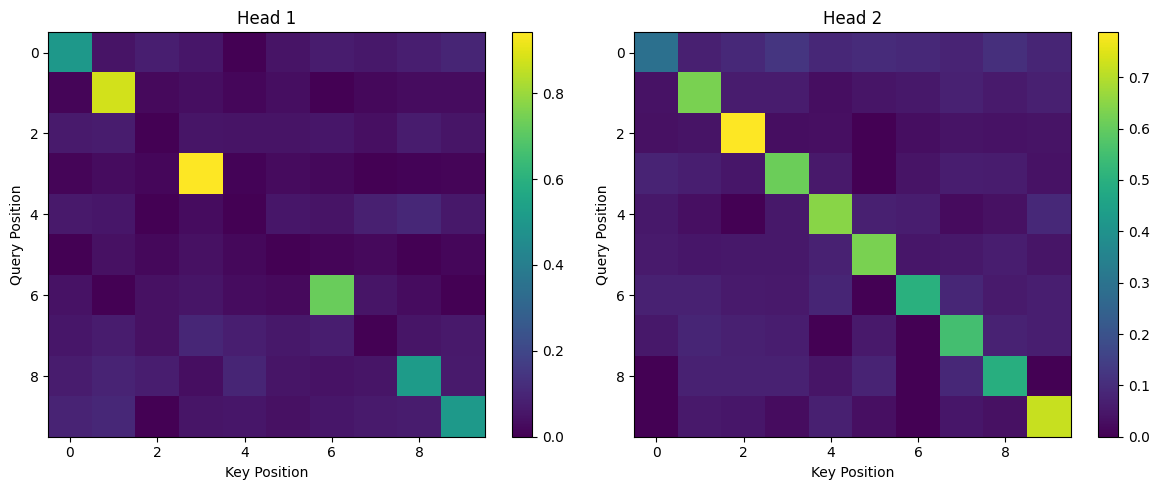

In [12]:
import matplotlib.pyplot as plt

attention_weights = multi_head_attention.attention_weights.detach()

plt.figure(figsize=(12, 5))

# Head 1
plt.subplot(1, 2, 1)
plt.imshow(attention_weights[0, 0], aspect="auto")
plt.colorbar()
plt.title("Head 1")
plt.xlabel("Key Position")
plt.ylabel("Query Position")

# Head 2
plt.subplot(1, 2, 2)
plt.imshow(attention_weights[0, 1], aspect="auto")
plt.colorbar()
plt.title("Head 2")
plt.xlabel("Key Position")
plt.ylabel("Query Position")

plt.tight_layout()
plt.show()

### The figure compares the attention weights produced by two different attention heads for the same input sequence. Each row represents a query token, and each column represents a key token. Brighter colors indicate higher attention weights.

### Both heads exhibit a strong diagonal pattern, meaning that tokens place significant attention on themselves. This behavior is expected because the input consists of randomly generated embeddings rather than meaningful language data.

### Despite processing the same input, Head 1 and Head 2 produce slightly different attention distributions. For example, some off-diagonal regions receive different attention weights in each head, indicating that the heads learn distinct ways of analyzing token relationships.

## 5.6 Add & Normalize Layer

### 5.6.1 Code

In [13]:
class AddNorm(nn.Module):
    def __init__(self, model_dimension, dropout_probability):
        super().__init__()
        self.norm = nn.LayerNorm(model_dimension) # normalization layer
        self.dropout = nn.Dropout(dropout_probability) # dropout used for regularization (reduce overfittin)

    def forward(self, x, sublayer_output):
        return self.norm(x + self.dropout(sublayer_output)) # apply and return

### 5.6.2 Results

In [14]:
fixed_seed()
add_norm = AddNorm(model_dimension=4, dropout_probability=0.5)

# Enable dropout
add_norm.train()

# small test data, batch size=1, sequence length=1, vector dimension=4

x = torch.tensor([
    [[1000., 2000., 3000., 4000.]]
])

sublayer_output = torch.tensor([
    [[5000., 6000., 7000., 8000.]]
])

# dropout
dropped = add_norm.dropout(sublayer_output)

# addition
added = x + dropped

# normalize
normalized = add_norm.norm(added)

print("Input x:")
print(x)

print("\nSublayer Output:")
print(sublayer_output)

print("\nAfter Dropout:")
print(dropped)

print("\nAfter Addition:")
print(added)

print("\nAfter LayerNorm:")
print(normalized)

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Data
before = added.detach().numpy().flatten()
after = normalized.detach().numpy().flatten()

print("\nBefore LayerNorm")
print(f"Mean = {before.mean():.2f}")
print(f"Std  = {before.std():.2f}")

print("\nAfter LayerNorm")
print(f"Mean = {after.mean():.6f}")
print(f"Std  = {after.std():.6f}")

Input x:
tensor([[[1000., 2000., 3000., 4000.]]])

Sublayer Output:
tensor([[[5000., 6000., 7000., 8000.]]])

After Dropout:
tensor([[[    0.,     0., 14000., 16000.]]])

After Addition:
tensor([[[ 1000.,  2000., 17000., 20000.]]])

After LayerNorm:
tensor([[[-1.0498, -0.9331,  0.8165,  1.1664]]],
       grad_fn=<NativeLayerNormBackward0>)

Before LayerNorm
Mean = 10000.00
Std  = 8573.21

After LayerNorm
Mean = 0.000000
Std  = 1.000000


**Dropout (p = 0.5)** randomly removes sets some values to zero and scales the remaining by:

$$
\frac{1}{1-p}=\frac{1}{1-0.5}=2
$$

```text
[5000, 6000, 7000, 8000] → [0, 0, 14000, 16000]
```

**Residual Addition** adds the original input to the dropout output:

```text
[1000, 2000, 3000, 4000] + [0, 0, 14000, 16000] = [1000, 2000, 1700, 20000]
```

**Layer Normalization** is then applied to the resulting vector usinng the equation:

$$
x_{norm}=\frac{x-\mu}{\sigma}
$$

which produces:

```text
[-1.0498, -0.9331,  0.8165,  1.1664]
```

Values larger than the mean become positive, while values smaller than the mean become negative. This normalization helps stabilize training and keeps activations at a consistent scale.

## 5.7 Feed Forward Neural Network

### 5.7.1 Code

In [15]:
class PositionwiseFeedForwardNet(nn.Module):
    def __init__(self, model_dimension=512, d_ff=2048):
        super().__init__()

        """
            This FFN is a full connected netowrk
            It has 1 hidden layer + output layer
            number of inputs = vector dimension (d)
            number of neurons in the hidden layer = d_ff
            number of neurons in the output layer = vector dimension (d)

            The same FFN is applied independently to every token position in the sequence.
        """

        self.linear1 = nn.Linear(model_dimension, d_ff)
        self.linear2 = nn.Linear(d_ff, model_dimension)
        
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.linear1(x))
        x = self.linear2(x)
        return x

### 5.7.2 Results

In [16]:
fixed_seed()
ffn = PositionwiseFeedForwardNet(model_dimension=4, d_ff=8)

# batch_size = 1
# sequence_length = 3
# model_dimension = 4
x = torch.tensor([
    [[1., 2., 3., 4.],
     [2., 3., 4., 5.],
     [3., 4., 5., 6.]],

    [[10., 20., 30., 40.],
     [20., 30., 40., 50.],
     [30., 40., 50., 60.]]
])

output = ffn(x)

print("Input shape:")
print(x.shape)

print("\nInput")
print(x)

print("\nOutput shape:")
print(output.shape)

print("\nOutput:")
print(output)

Input shape:
torch.Size([2, 3, 4])

Input
tensor([[[ 1.,  2.,  3.,  4.],
         [ 2.,  3.,  4.,  5.],
         [ 3.,  4.,  5.,  6.]],

        [[10., 20., 30., 40.],
         [20., 30., 40., 50.],
         [30., 40., 50., 60.]]])

Output shape:
torch.Size([2, 3, 4])

Output:
tensor([[[ 1.1182e+00, -3.6057e-01, -1.6384e-01, -1.4436e-01],
         [ 1.6008e+00, -6.0104e-01,  2.3859e-02, -1.5434e-02],
         [ 2.0835e+00, -8.4152e-01,  2.1155e-01,  1.1350e-01]],

        [[ 7.6198e+00, -2.4382e+00,  3.0985e+00,  2.6504e+00],
         [ 1.2446e+01, -4.8429e+00,  4.9755e+00,  3.9397e+00],
         [ 1.7273e+01, -7.2477e+00,  6.8524e+00,  5.2290e+00]]],
       grad_fn=<ViewBackward0>)


The FFN computation is:

FFN(x) = max(0, xW₁ + b₁)W₂ + b₂

where:

- x: input token representation
- W₁, b₁: weights and bias of the first linear layer
- W₂, b₂: weights and bias of the second linear layer

The FFN keeps the same input and output shape: `[1, 3, 4]`.

Internally, each token vector is transformed independently, o each token starts with 4 features and also ends with 4 features.

This shows that the FFN changes the representation of each token while preserving the same model dimension.

## 5.8 Encoder

### 5.8.1 Code

#### 5.8.1.1 One Encoder Layer

In [17]:
class EncoderLayer(nn.Module):
    def __init__(self, model_dimension, dropout_probability,
                 multi_head_attention, feed_forward):
        super().__init__()

        # Encoder has two main sublayers:
        # 1. Multi-head self-attention
        # 2. Position-wise feed-forward network

        self.self_attention = multi_head_attention
        self.feed_forward = feed_forward

        # Add & Norm after each sublayer
        self.add_norm = AddNorm(model_dimension, dropout_probability)

    def forward(self, x, src_mask=None):

        # Self-attention: Q, K, V all come from the same input x
        attention_output = self.self_attention(
            query=x,
            key=x,
            value=x,
            mask=src_mask
        )

        # Residual connection + dropout + layer normalization
        x = self.add_norm(x, attention_output)

        # Feed-forward network
        ffn_output = self.feed_forward(x)

        # Residual connection + dropout + layer normalization
        x = self.add_norm(x, ffn_output)

        return x

#### 5.8.1.2 Stacked Encoder

In [18]:
class Encoder(nn.Module):
    def __init__(self, encoder_layer, number_of_layers):
        super().__init__()

        # Make independent copies of the encoder layer
        self.layers = get_clones(encoder_layer, number_of_layers)

    def forward(self, x, src_mask=None):

        # Pass through all encoder layers one by one
        for layer in self.layers:
            x = layer(x, src_mask)

        return x

### 5.8.2 Results

In [20]:
fixed_seed()

model_dimension = 512
number_of_heads = 8
dropout_probability = 0.1
number_of_layers = 6

mha = MultiHeadedAttention(
    model_dimension=model_dimension,
    number_of_heads=number_of_heads,
    dropout_probability=dropout_probability,
    log_attention_weights=True
)

ffn = PositionwiseFeedForwardNet(
    model_dimension=model_dimension,
    d_ff=2048
)

encoder_layer = EncoderLayer(
    model_dimension=model_dimension,
    dropout_probability=dropout_probability,
    multi_head_attention=mha,
    feed_forward=ffn
)

encoder = Encoder(
    encoder_layer=encoder_layer,
    number_of_layers=number_of_layers
)

x = torch.randn(2, 10, model_dimension)

out = encoder(x, src_mask=None)

print("Input shape:", x.shape)
print("Encoder output shape:", out.shape)

Input shape: torch.Size([2, 10, 512])
Encoder output shape: torch.Size([2, 10, 512])


## 5.9 Decoder

### 5.9.1 Code

#### 5.9.1.1 One Decoder Layer

In [20]:
class DecoderLayer(nn.Module):

    def __init__(self, model_dimension, dropout_probability,
                 multi_head_attention, feed_forward):
        super().__init__()

        # Decoder has three main sublayers:
        # 1. Masked multi-head self-attention
        # 2. Multi-head attention over the encoder output
        # 3. Position-wise feed-forward network

        self.target_attention = copy.deepcopy(multi_head_attention)
        self.source_attention = copy.deepcopy(multi_head_attention)
        self.feed_forward = feed_forward

        # Add & Norm after each sublayer
        self.add_norms = get_clones(
            AddNorm(model_dimension, dropout_probability), 3
        )

    def forward(self, x, encoder_output, trg_mask=None, src_mask=None):

        # Masked self-attention: Q, K, V all come from the target input
        target_attention_output = self.target_attention(
            query=x,
            key=x,
            value=x,
            mask=trg_mask
        )
        x = self.add_norms[0](x, target_attention_output)

        # Encoder-decoder attention: Q comes from the decoder,
        # while K and V come from the encoder output
        source_attention_output = self.source_attention(
            query=x,
            key=encoder_output,
            value=encoder_output,
            mask=src_mask
        )
        x = self.add_norms[1](x, source_attention_output)

        # Feed-forward network
        ffn_output = self.feed_forward(x)
        x = self.add_norms[2](x, ffn_output)

        return x

#### 5.9.1.2 Stacked Decoder

In [21]:
class Decoder(nn.Module):

    def __init__(self, decoder_layer, number_of_layers):
        super().__init__()

        # Make independent copies of the decoder layer
        self.layers = get_clones(decoder_layer, number_of_layers)

    def forward(self, x, encoder_output, trg_mask=None, src_mask=None):

        # Pass through all decoder layers one by one
        for layer in self.layers:
            x = layer(x, encoder_output, trg_mask, src_mask)

        return x

### 5.9.2 Results

In [22]:
fixed_seed()

model_dimension = 512
number_of_heads = 8
dropout_probability = 0.1
number_of_layers = 6

mha = MultiHeadedAttention(
    model_dimension=model_dimension,
    number_of_heads=number_of_heads,
    dropout_probability=dropout_probability,
    log_attention_weights=True
)

ffn = PositionwiseFeedForwardNet(
    model_dimension=model_dimension,
    d_ff=2048
)

decoder_layer = DecoderLayer(
    model_dimension=model_dimension,
    dropout_probability=dropout_probability,
    multi_head_attention=mha,
    feed_forward=ffn
)

decoder = Decoder(
    decoder_layer=decoder_layer,
    number_of_layers=number_of_layers
)

target_x = torch.randn(2, 8, model_dimension)
encoder_output = torch.randn(2, 10, model_dimension)

out = decoder(
    target_x,
    encoder_output,
    trg_mask=None,
    src_mask=None
)

print("Target input shape:", target_x.shape)
print("Encoder output shape:", encoder_output.shape)
print("Decoder output shape:", out.shape)

Target input shape: torch.Size([2, 8, 512])
Encoder output shape: torch.Size([2, 10, 512])
Decoder output shape: torch.Size([2, 8, 512])


## 5.10 Decoder Generator (Linear + Softmax)

### 5.10.1 Code

In [23]:
class DecoderGenerator(nn.Module):
    def __init__(self, model_dimension, vocab_size):
        super().__init__()

        # Project each decoder representation to the target vocabulary size
        self.linear = nn.Linear(model_dimension, vocab_size)

        # Apply log-softmax over the vocabulary dimension
        self.log_softmax = nn.LogSoftmax(dim=-1)

    def forward(self, target_representations):
        return self.log_softmax(self.linear(target_representations))

### 5.10.2 Results

In [24]:
fixed_seed()

model_dimension = 512
target_vocab_size = 8000

decoder_generator = DecoderGenerator(
    model_dimension=model_dimension,
    vocab_size=target_vocab_size
)

decoder_output = torch.randn(2, 8, model_dimension)
log_probabilities = decoder_generator(decoder_output)

print("Decoder output shape:", decoder_output.shape)
print("Log probabilities shape:", log_probabilities.shape)

Decoder output shape: torch.Size([2, 8, 512])
Log probabilities shape: torch.Size([2, 8, 8000])


## 5.11 Complete Transformer Model

### 5.11.1 Code

In [25]:
class Transformer(nn.Module):

    def __init__(
        self,
        model_dimension,
        src_vocab_size,
        trg_vocab_size,
        number_of_heads,
        number_of_layers,
        dropout_probability,
        log_attention_weights=False
    ):
        super().__init__()

        # Source and target token embeddings
        self.src_embedding = Embedding(src_vocab_size, model_dimension)
        self.trg_embedding = Embedding(trg_vocab_size, model_dimension)

        # Add positional information to embeddings
        self.src_pos_embedding = PositionalEncoding(model_dimension, dropout_probability)
        self.trg_pos_embedding = PositionalEncoding(model_dimension, dropout_probability)

        # Shared building blocks used to construct encoder and decoder layers
        mha = MultiHeadedAttention(
            model_dimension,
            number_of_heads,
            dropout_probability,
            log_attention_weights
        )

        ffn = PositionwiseFeedForwardNet(
            model_dimension=model_dimension,
            d_ff=4 * model_dimension
        )

        # Build encoder and decoder layers
        encoder_layer = EncoderLayer(
            model_dimension,
            dropout_probability,
            mha,
            ffn
        )

        decoder_layer = DecoderLayer(
            model_dimension,
            dropout_probability,
            mha,
            ffn
        )

        # Stack multiple encoder and decoder layers
        self.encoder = Encoder(encoder_layer, number_of_layers)
        self.decoder = Decoder(decoder_layer, number_of_layers)

        # Convert decoder outputs to vocabulary log-probabilities
        self.decoder_generator = DecoderGenerator(model_dimension, trg_vocab_size)

        self.init_params()

    def init_params(self):
        # Xavier initialization for trainable weight matrices
        for param in self.parameters():
            if param.dim() > 1:
                nn.init.xavier_uniform_(param)

    def encode(self, src_token_ids_batch, src_mask=None):
        src_embeddings = self.src_embedding(src_token_ids_batch)
        src_embeddings = self.src_pos_embedding(src_embeddings)

        encoder_output = self.encoder(src_embeddings, src_mask)

        return encoder_output

    def decode(self, trg_token_ids_batch, encoder_output, trg_mask=None, src_mask=None):
        trg_embeddings = self.trg_embedding(trg_token_ids_batch)
        trg_embeddings = self.trg_pos_embedding(trg_embeddings)

        decoder_output = self.decoder(
            trg_embeddings,
            encoder_output,
            trg_mask,
            src_mask
        )

        trg_log_probs = self.decoder_generator(decoder_output)

        return trg_log_probs

    def forward(self, src_token_ids_batch, trg_token_ids_batch, src_mask=None, trg_mask=None):
        encoder_output = self.encode(src_token_ids_batch, src_mask)

        trg_log_probs = self.decode(
            trg_token_ids_batch,
            encoder_output,
            trg_mask,
            src_mask
        )

        return trg_log_probs

### 5.11.2 Results

Source input shape: torch.Size([3, 5])
Target input shape: torch.Size([3, 4])
Transformer output shape: torch.Size([3, 4, 11])


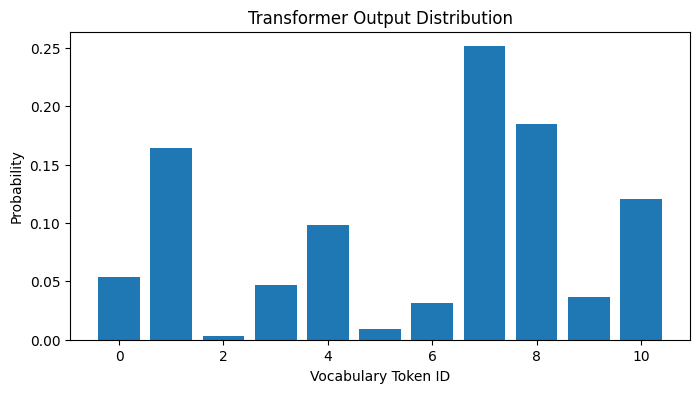

In [26]:
src_vocab_size = 11
trg_vocab_size = 11

model_dimension = 512
number_of_heads = 8
number_of_layers = 2
dropout_probability = 0.1

batch_size = 3
src_sequence_length = 5
trg_sequence_length = 4

src_token_ids_batch = torch.randint(
    1,
    src_vocab_size,
    size=(batch_size, src_sequence_length)
)

trg_token_ids_batch = torch.randint(
    1,
    trg_vocab_size,
    size=(batch_size, trg_sequence_length)
)

transformer = Transformer(
    model_dimension=model_dimension,
    src_vocab_size=src_vocab_size,
    trg_vocab_size=trg_vocab_size,
    number_of_heads=number_of_heads,
    number_of_layers=number_of_layers,
    dropout_probability=dropout_probability
)

output = transformer(
    src_token_ids_batch,
    trg_token_ids_batch
)

print("Source input shape:", src_token_ids_batch.shape)
print("Target input shape:", trg_token_ids_batch.shape)
print("Transformer output shape:", output.shape)

with torch.no_grad():
    probs = torch.softmax(output[0, 0], dim=-1)

plt.figure(figsize=(8,4))
plt.bar(range(len(probs)), probs.detach().numpy())
plt.xlabel("Vocabulary Token ID")
plt.ylabel("Probability")
plt.title("Transformer Output Distribution")
plt.show()



# 6. Data

## 6.1 Dataset Selection

We selected **[Multi30K English–German](https://github.com/multi30k/dataset)**, which provides approximately **29,000 professionally translated training pairs** with established validation and test splits. Its short captions and text-only setup make it practical for training a reduced Transformer on limited hardware.

**Other Possible Approaches and Why We Did Not Choose Them**

1. **Full WMT14 English–German Dataset**  
   **Reason for rejection:** Its roughly 4.5 million sentence pairs demand excessive computation, storage, and preprocessing.

2. **A Small WMT14 Subset**  
   **Reason for rejection:** It is difficult to reconstruct reliably, while sampling and retraining the tokenizer would reduce representativeness and comparability.

**Scope.** Multi30K offers the best balance of feasibility, reproducibility, and meaningful results while supporting the complete Transformer pipeline. Because its domain is image captions rather than news, its BLEU scores cannot be compared directly with the original paper; this is a **small-scale architectural demonstration**, not a performance reproduction.

## 6.2 Data Preprocessing

The following layers transform one real Multi30K pair from raw text into tensors ready for the Transformer. Capitalization and punctuation are preserved throughout.

**Running example**

- EN: `Two young, White males are outside near many bushes.`
- DE: `Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.`

### 6.2.1 Raw Loading Layer


Reads matching lines directly from the compressed English and German files and joins them as one translation pair.

`train.en.gz + train.de.gz` → `(English sentence, German sentence)`


### 6.2.2 Unicode and Whitespace Normalization Layer


Applies NFC Unicode normalization, removes surrounding whitespace, and collapses repeated spaces without lowercasing or changing punctuation.

`Two young, White males ...` → `Two young, White males ...` *(unchanged for this example)*


### 6.2.3 Training Filtering Layer


Removes only unsuitable training pairs: empty text, more than 40 words, an EN–DE length ratio above 2, or an exact duplicate. Evaluation splits remain unfiltered.

`9 EN words, 12 DE words, ratio = 1.33` → `kept`

This retained **28,962** of the original **29,000** training pairs.


### 6.2.4 Clean Saving Layer


Writes the cleaned pair to aligned UTF-8 files while leaving the raw archives unchanged.

`(clean EN, clean DE)` → `train.en` and `train.de` on the same line number


### 6.2.5 Shared BPE Layer


A shared 8,000-piece SentencePiece BPE model, trained only on the English and German training files, splits rare words into reusable subwords. The `▁` symbol marks a word boundary.

- EN output: `▁Two ▁young , ▁White ▁males ▁are ▁outside ▁near ▁many ▁bushes .`
- DE output: `▁Zwei ▁junge ▁weiße ▁Männer ▁sind ▁im ▁Freien ▁in ▁der ▁Nähe ▁viel er ▁Bü sche .`


### 6.2.6 Token-ID Layer


Maps every BPE piece to its fixed integer ID from the shared vocabulary.

- EN output: `[161, 216, 7931, 5393, 3956, 132, 457, 574, 1857, 6086, 7917]`
- DE output: `[156, 690, 1663, 251, 705, 159, 734, 18, 115, 837, 1728, 7, 2038, 1266, 7917]`


### 6.2.7 Special-Token and Decoder-Shift Layer


Uses `<pad>=0`, `<unk>=1`, `<s>=2`, and `</s>=3`. The German sequence is shifted so the decoder predicts the next token rather than seeing it in advance.

- Encoder input: `[2, 161, 216, ..., 7917, 3]`
- Decoder input: `[2, 156, 690, ..., 1266, 7917]`
- Expected output: `[156, 690, ..., 1266, 7917, 3]`

Thus, `<s>` predicts `▁Zwei`, `▁Zwei` predicts `▁junge`, and the final period predicts `</s>`.


### 6.2.8 Dynamic Padding Layer



Pads shorter sequences only to the longest sequence in their batch.

`[2, 161, ..., 7917, 3]` → `[2, 161, ..., 7917, 3, 0, 0]`



### 6.2.9 Attention-Mask Layer



The source mask hides padding. The target mask hides both padding and future German tokens.

Source mask: `[1, 1, ..., 1, 0, 0]`

Causal target mask:

```text
1 0 0 0
1 1 0 0
1 1 1 0
1 1 1 1
```


### 6.2.10 Final Batch Output Layer



The data loader outputs `source_ids`, `decoder_input_ids`, `labels`, `source_mask`, and `target_mask` tensors. These are the final preprocessing outputs passed directly to the Transformer.

## 6.3 Exploratory Data Analysis (EDA)

### Dataset Retention

| Measure | Result |
|---|---:|
| Original training pairs | 29,000 |
| Cleaned training pairs | 28,962 |
| Length-ratio outliers removed | 35 |
| Exact duplicates removed | 3 |
| Total pairs removed | 38 |
| Training data retained | 99.87% |

The high retention rate indicates that the raw Multi30K parallel corpus was already well aligned; cleaning removed only a small number of anomalous or repeated pairs.

### Normalization Impact

| Split | Pairs changed by Unicode/whitespace normalization |
|---|---:|
| Train | 130 |
| Validation | 1 |
| Test | 0 |

Only a small fraction required normalization, and capitalization and punctuation were preserved.

### BPE Statistics

| Measure | English | German |
|---|---:|---:|
| Training BPE pieces | 413,489 | 428,031 |
| Average pieces per training sentence | 14.28 | 14.78 |
| Shared vocabulary size | 8,000 | 8,000 |
| Unknown pieces across train/validation/test | 0 | 0 |

German produced slightly longer BPE sequences, consistent with its productive compounding and inflection. Zero unknown pieces show that the shared tokenizer covers every project split.

### Most Frequent Training BPE Pieces

| Rank | English piece | Count | German piece | Count |
|---:|---|---:|---|---:|
| 1 | `▁a` | 31,771 | `.` | 28,755 |
| 2 | `.` | 27,570 | `▁Ein` | 13,960 |
| 3 | `▁A` | 17,497 | `▁einem` | 13,692 |
| 4 | `▁in` | 14,905 | `▁in` | 11,864 |
| 5 | `▁the` | 9,907 | `,` | 8,937 |
| 6 | `▁on` | 8,019 | `▁und` | 8,927 |
| 7 | `▁is` | 7,523 | `▁mit` | 8,837 |
| 8 | `▁man` | 7,402 | `▁auf` | 8,830 |
| 9 | `▁and` | 7,373 | `▁Mann` | 7,817 |
| 10 | `▁of` | 6,854 | `▁einer` | 6,748 |

The most frequent pieces are punctuation, articles, prepositions, and common caption words. Separate `▁a` and `▁A` pieces also confirm that capitalization was retained.

# 7. Experiments

#### No need to run section 7 again, results are saved in the csv file

## 7.1 Dataset Setup

In [27]:
from pathlib import Path

path = "./data/processed/multi30k_en_de_bpe8000"
taleed_path = "C:/Users/ASUS/NLP_PROJ/data/processed/multi30k_en_de_bpe8000"

data_dir = Path(path)

train_de_path = data_dir / "train.bpe.de"
train_en_path = data_dir / "train.bpe.en"

val_de_path = data_dir / "val.bpe.de"
val_en_path = data_dir / "val.bpe.en"

test_de_path = data_dir / "test_2016_flickr.bpe.de"
test_en_path = data_dir / "test_2016_flickr.bpe.en"

def read_lines(path):
    with open(path, "r", encoding="utf-8") as f:
        return [line.strip() for line in f]

train_de = read_lines(train_de_path)
train_en = read_lines(train_en_path)

val_de = read_lines(val_de_path)
val_en = read_lines(val_en_path)

test_de = read_lines(test_de_path)
test_en = read_lines(test_en_path)

print("Training pairs:", len(train_de))
print("Validation pairs:", len(val_de))
print("Test pairs:", len(test_de))

print("\nExample:")
print("German :", train_de[0])
print("English:", train_en[0])

Training pairs: 28962
Validation pairs: 1014
Test pairs: 1000

Example:
German : ▁Zwei ▁junge ▁weiße ▁Männer ▁sind ▁im ▁Freien ▁in ▁der ▁Nähe ▁viel er ▁Bü sche .
English: ▁Two ▁young , ▁White ▁males ▁are ▁outside ▁near ▁many ▁bushes .


## 7.2 Vocabulary Loading

In [28]:
PAD_TOKEN = "<pad>"
SOS_TOKEN = "<s>"
EOS_TOKEN = "</s>"
UNK_TOKEN = "<unk>"

SPECIAL_TOKENS = [PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN]

def load_bpe_vocab(vocab_path):
    vocab = {}

    for token in SPECIAL_TOKENS:
        vocab[token] = len(vocab)

    with open(vocab_path, "r", encoding="utf-8") as f:
        for line in f:
            token = line.strip().split()[0]

            if token not in vocab:
                vocab[token] = len(vocab)

    return vocab

vocab = load_bpe_vocab(data_dir / "shared_bpe.vocab")

PAD_IDX = vocab[PAD_TOKEN]
SOS_IDX = vocab[SOS_TOKEN]
EOS_IDX = vocab[EOS_TOKEN]
UNK_IDX = vocab[UNK_TOKEN]

idx_to_token = {idx: token for token, idx in vocab.items()}

print("Vocabulary size:", len(vocab))
print("PAD index:", PAD_IDX)
print("SOS index:", SOS_IDX)
print("EOS index:", EOS_IDX)
print("UNK index:", UNK_IDX)

Vocabulary size: 8000
PAD index: 0
SOS index: 1
EOS index: 2
UNK index: 3


## 7.3 Dataset Encoding

In [29]:
def encode_bpe_sentence(sentence, vocab, max_len=50):
    tokens = sentence.split()

    ids = [SOS_IDX]
    ids += [vocab.get(token, UNK_IDX) for token in tokens]
    ids += [EOS_IDX]

    return ids[:max_len]

sample_de_ids = encode_bpe_sentence(train_de[0], vocab)
sample_en_ids = encode_bpe_sentence(train_en[0], vocab)

print("German sentence:")
print(train_de[0])

print("\nEncoded German:")
print(sample_de_ids)

print("\nEnglish sentence:")
print(train_en[0])

print("\nEncoded English:")
print(sample_en_ids)

German sentence:
▁Zwei ▁junge ▁weiße ▁Männer ▁sind ▁im ▁Freien ▁in ▁der ▁Nähe ▁viel er ▁Bü sche .

Encoded German:
[1, 156, 690, 1663, 251, 705, 159, 734, 18, 115, 837, 1728, 7, 2038, 1266, 7917, 2]

English sentence:
▁Two ▁young , ▁White ▁males ▁are ▁outside ▁near ▁many ▁bushes .

Encoded English:
[1, 161, 216, 7931, 5393, 3956, 132, 457, 574, 1857, 6086, 7917, 2]


## 7.4 DataLoader Construction

In [30]:
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

class TranslationDataset(Dataset):
    def __init__(self, src_sentences, trg_sentences, vocab, max_len=50):
        self.src_sentences = src_sentences
        self.trg_sentences = trg_sentences
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.src_sentences)

    def __getitem__(self, idx):
        src_ids = encode_bpe_sentence(
            self.src_sentences[idx],
            self.vocab,
            self.max_len
        )

        trg_ids = encode_bpe_sentence(
            self.trg_sentences[idx],
            self.vocab,
            self.max_len
        )

        return torch.tensor(src_ids), torch.tensor(trg_ids)

def collate_batch(batch):
    src_batch, trg_batch = zip(*batch)

    src_batch = pad_sequence(
        src_batch,
        batch_first=True,
        padding_value=PAD_IDX
    )

    trg_batch = pad_sequence(
        trg_batch,
        batch_first=True,
        padding_value=PAD_IDX
    )

    return src_batch, trg_batch

In [31]:
batch_size = 32
max_len = 50

train_dataset = TranslationDataset(train_de, train_en, vocab, max_len)
val_dataset = TranslationDataset(val_de, val_en, vocab, max_len)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_batch
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_batch
)

src_batch, trg_batch = next(iter(train_loader))

print("Source batch shape:", src_batch.shape)
print("Target batch shape:", trg_batch.shape)

Source batch shape: torch.Size([32, 38])
Target batch shape: torch.Size([32, 27])


## 7.5 Mask Creation

In [32]:
def create_src_mask(src):
    return (src != PAD_IDX).unsqueeze(1).unsqueeze(2)

def create_trg_mask(trg):
    batch_size, trg_len = trg.shape

    pad_mask = (trg != PAD_IDX).unsqueeze(1).unsqueeze(2)

    future_mask = torch.tril(
        torch.ones((trg_len, trg_len), device=trg.device)
    ).bool()

    return pad_mask & future_mask

In [33]:
trg_input = trg_batch[:, :-1]

src_mask = create_src_mask(src_batch)
trg_mask = create_trg_mask(trg_input)

print("Source mask shape:", src_mask.shape)
print("Target mask shape:", trg_mask.shape)

Source mask shape: torch.Size([32, 1, 1, 38])
Target mask shape: torch.Size([32, 1, 26, 26])


## 7.6 Training Configuration

In [34]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model_dimension = 128
number_of_heads = 4
number_of_layers = 2
dropout_probability = 0.1

transformer = Transformer(
    model_dimension=model_dimension,
    src_vocab_size=len(vocab),
    trg_vocab_size=len(vocab),
    number_of_heads=number_of_heads,
    number_of_layers=number_of_layers,
    dropout_probability=dropout_probability
).to(device)

criterion = torch.nn.NLLLoss(ignore_index=PAD_IDX)

optimizer = torch.optim.Adam(
    transformer.parameters(),
    lr=0.0003
)

total_params = sum(p.numel() for p in transformer.parameters() if p.requires_grad)

print(f"Trainable parameters: {total_params:,}")

Device: cuda
Trainable parameters: 4,005,184


## 7.7 Training Loop

In [35]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0

    for src, trg in dataloader:
        src = src.to(device)
        trg = trg.to(device)

        trg_input = trg[:, :-1]
        trg_output = trg[:, 1:]

        src_mask = create_src_mask(src).to(device)
        trg_mask = create_trg_mask(trg_input).to(device)

        optimizer.zero_grad()

        output = model(src, trg_input, src_mask, trg_mask)

        output = output.reshape(-1, output.shape[-1])
        trg_output = trg_output.reshape(-1)

        loss = criterion(output, trg_output)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)

## 7.8 Validation

In [36]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for src, trg in dataloader:
            src = src.to(device)
            trg = trg.to(device)

            trg_input = trg[:, :-1]
            trg_output = trg[:, 1:]

            src_mask = create_src_mask(src).to(device)
            trg_mask = create_trg_mask(trg_input).to(device)

            output = model(src, trg_input, src_mask, trg_mask)

            output = output.reshape(-1, output.shape[-1])
            trg_output = trg_output.reshape(-1)

            loss = criterion(output, trg_output)

            total_loss += loss.item()

    return total_loss / len(dataloader)

## 7.9 Run Training

In [37]:
num_epochs = 5

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    train_loss = train_one_epoch(
        transformer,
        train_loader,
        optimizer,
        criterion,
        device
    )

    val_loss = evaluate(
        transformer,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss:   {val_loss:.4f}")
    print("-" * 30)

Epoch 1/5
Train Loss: 4.7012
Val Loss:   3.5418
------------------------------
Epoch 2/5
Train Loss: 3.2695
Val Loss:   2.8217
------------------------------
Epoch 3/5
Train Loss: 2.7178
Val Loss:   2.4329
------------------------------
Epoch 4/5
Train Loss: 2.3548
Val Loss:   2.1819
------------------------------
Epoch 5/5
Train Loss: 2.0907
Val Loss:   2.0301
------------------------------


## 7.10 Training Curve Figure

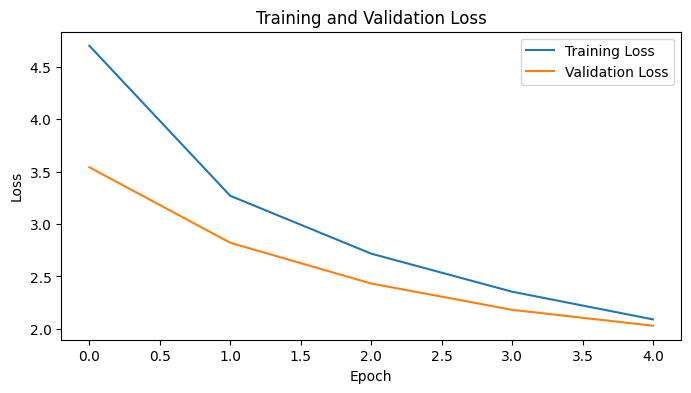

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

# 8. Results


#### No need to run section 8 again, results are saved in the csv file

In [39]:
def decode_ids(token_ids, idx_to_token):
    tokens = []

    for idx in token_ids:
        token = idx_to_token.get(int(idx), "<UNK>")

        if token in ["<PAD>", "<SOS>"]:
            continue

        if token == "<EOS>":
            break

        tokens.append(token)

    return " ".join(tokens)

In [40]:
def translate_sentence(model, src_sentence, vocab, idx_to_token, device, max_len=50):
    model.eval()

    src_ids = encode_bpe_sentence(src_sentence, vocab, max_len)

    src_tensor = torch.tensor(src_ids).unsqueeze(0).to(device)

    src_mask = create_src_mask(src_tensor).to(device)

    trg_ids = [SOS_IDX]

    with torch.no_grad():

        for _ in range(max_len):

            trg_tensor = torch.tensor(trg_ids).unsqueeze(0).to(device)

            trg_mask = create_trg_mask(trg_tensor).to(device)

            output = model(
                src_tensor,
                trg_tensor,
                src_mask,
                trg_mask
            )

            next_token = output[0, -1].argmax(-1).item()

            trg_ids.append(next_token)

            if next_token == EOS_IDX:
                break

    return decode_ids(trg_ids, idx_to_token)

In [41]:
import os
import builtins
import csv


sources = []
references = []
predictions = []

print("Test pairs:", len(test_de))

for i in range(len(test_de)):
    prediction = translate_sentence(
        transformer,
        test_de[i],
        vocab,
        idx_to_token,
        device
    )

    sources.append(test_de[i])
    references.append(test_en[i])
    predictions.append(prediction)

    if i < 10:
        print(f"Example {i+1}")
        print("German Input:      ", test_de[i])
        print("Reference English: ", test_en[i])
        print("Model Prediction:  ", prediction)
        print("-" * 70)


Test pairs: 1000
Example 1
German Input:       ▁Ein ▁Mann ▁mit ▁einem ▁orangefarbenen ▁Hut , ▁der ▁etwas ▁an st ar rt .
Reference English:  ▁A ▁man ▁in ▁an ▁orange ▁hat ▁star ring ▁at ▁something .
Model Prediction:   <s> ▁A ▁man ▁in ▁an ▁orange ▁hat ▁looking ▁at ▁something . </s>
----------------------------------------------------------------------
Example 2
German Input:       ▁Ein ▁Bo st on ▁T err ier ▁läuft ▁über ▁s aft ig - grü nes ▁Gras ▁vor ▁einem ▁weißen ▁Zaun .
Reference English:  ▁A ▁Bo st on ▁T err ier ▁is ▁running ▁on ▁l ush ▁green ▁grass ▁in ▁front ▁of ▁a ▁white ▁fence .
Model Prediction:   <s> ▁A ▁body ▁of ▁water ▁with ▁t - p o ▁running ▁over ▁the ▁grass ▁and ▁green ▁grass ▁in ▁front ▁of ▁a ▁white ▁fence . </s>
----------------------------------------------------------------------
Example 3
German Input:       ▁Ein ▁Mädchen ▁in ▁einem ▁Karate anzug ▁br icht ▁ein ▁Brett ▁mit ▁einem ▁Tr itt .
Reference English:  ▁A ▁girl ▁in ▁karate ▁uniform ▁bre aking ▁a ▁stick ▁with ▁a ▁f

In [43]:
with open("translation_predictions.csv", "w", encoding="utf-8", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["German Input", "Reference English", "Model Prediction"])
    writer.writerows(zip(sources, references, predictions))

print("Saved to translation_predictions.csv")

Saved to translation_predictions.csv


# 9. Analysis & Conclusion

**BLEU Metric**

The performance of the translation model was evaluated using the **Bilingual Evaluation Understudy (BLEU)** metric, which is one of the most widely used evaluation measures in machine translation.

BLEU measures the similarity between the generated translation and one or more reference translations by comparing matching word sequences (n-grams). The metric considers unigram, bigram, trigram, and four-gram matches, rewarding translations that contain phrases similar to those found in the reference text.

The BLEU score ranges from 0 to 100, where higher values indicate greater similarity between the generated and reference translations. In addition, BLEU applies a brevity penalty to discourage overly short translations that may achieve high n-gram precision by omitting important information.

The BLEU score is computed as:

$$
BLEU = BP \cdot \exp\left(\sum_{n=1}^{4} w_n \log p_n\right)
$$

where:

- $BP$ is the brevity penalty,
- $p_n$ is the modified n-gram precision,
- $w_n$ is the weight assigned to each n-gram order (typically $\frac{1}{4}$ for each of the four n-grams).

A higher BLEU score generally indicates better translation quality, although the metric does not directly measure semantic understanding or grammatical correctness. Therefore, BLEU is often complemented with qualitative analysis of translation examples.

In [2]:
import pandas as pd
import re
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

df = pd.read_csv("translation_predictions.csv")

def detok_bpe(text):
    text = str(text)
    text = re.sub(r"</?s>|<pad>|<unk>", " ", text)
    text = "".join(text.split())      # join BPE pieces
    text = text.replace("▁", " ")     # SentencePiece space marker
    text = re.sub(r"\s+", " ", text).strip()
    return text

references = [
    [detok_bpe(ref).split()]
    for ref in df["Reference English"]
]

predictions = [
    detok_bpe(pred).split()
    for pred in df["Model Prediction"]
]

bleu = corpus_bleu(
    references,
    predictions,
    smoothing_function=SmoothingFunction().method1
)

print(f"BLEU score: {bleu * 100:.2f}")

BLEU score: 31.80


The Transformer achieved a BLEU score of

$$
\text{BLEU} = 31.8
$$

on the Multi30k English–German test set.

This score suggests that the model generates translations that closely resemble the reference translations at both the word and phrase levels. In many cases, the model preserves the overall meaning of the source sentence while producing fluent English output.

**Reference to the Original Transformer Paper**

For context, Vaswani et al. reported **27.3 BLEU** for the Transformer base model and **28.4 BLEU** for the Transformer big model on the WMT 2014 English-German translation task. They also reported **41.8 BLEU** on WMT 2014 English-French. These numbers are not directly comparable to our result because the original paper used different datasets, larger model configurations, longer training schedules, and significantly more computational resources. They are included only as historical reference values from the original work.

**Example 1: Successful Translation**

**German Input**

> Ein Mann mit einem orangefarbenen Hut, der etwas anstarrt.

**Reference Translation**

> A man in an orange hat staring at something.

**Model Prediction**

> A man in an orange hat looking at something.

**Discussion**

The model successfully translated the key entities and actions in the sentence. Although the verb differs slightly (*looking at* instead of *staring at*), the overall meaning is preserved and the generated translation remains natural and fluent.

---

**Example 2: Partial Translation Error**

**German Input**

> Fünf Leute in Winterjacken und mit Helmen stehen im Schnee mit Schneemobilen im Hintergrund.

**Reference Translation**

> Five people wearing winter jackets and helmets stand in the snow, with snowmobiles in the background.

**Model Prediction**

> Five people in winter jackets and helmets are standing in the snow with snow in the background.

**Discussion**

The model correctly translated the people, clothing, and snowy environment. However, it failed to translate the word *snowmobiles*, replacing it with *snow*. While the main scene is preserved, an small detail is lost.

---

**Example 3: Translation Failure**

**German Input**

> Ein Boston Terrier läuft über saftig-grünes Gras vor einem weißen Zaun.

**Reference Translation**

> A Boston Terrier is running on lush green grass in front of a white fence.

**Model Prediction**

> A body of water with t-po running over the grass and green grass in front of a white fence.

**Discussion**

In this example, the model fails to preserve the meaning of the source sentence. The sentence is not translated correctly and unrelated phrases such as *body of water* are introduced. Although part of the scene description is retained, the generated translation is largely incorrect.

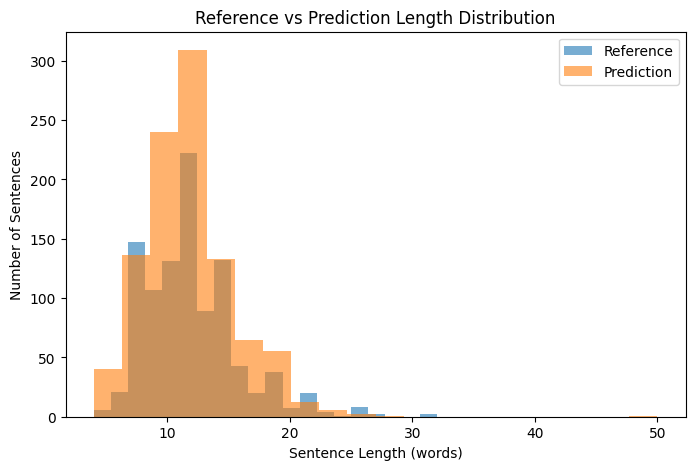

In [4]:
import csv
import re
import matplotlib.pyplot as plt

csv_path = r"translation_predictions.csv"

def detok_bpe(text):
    text = str(text)
    text = re.sub(r"</?s>|<pad>|<unk>", " ", text)
    text = "".join(text.split())
    text = text.replace("▁", " ")
    text = re.sub(r"\s+", " ", text).strip()
    return text

rows = []

with open(csv_path, "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)

    for row in reader:
        src = detok_bpe(row["German Input"])
        ref = detok_bpe(row["Reference English"])
        pred = detok_bpe(row["Model Prediction"])

        ref_tokens = ref.split()
        pred_tokens = pred.split()

        overlap = len(set(ref_tokens) & set(pred_tokens)) / max(len(set(ref_tokens)), 1)

        rows.append({
            "src": src,
            "ref": ref,
            "pred": pred,
            "ref_len": len(ref_tokens),
            "pred_len": len(pred_tokens),
            "overlap": overlap
        })

ref_lengths = [r["ref_len"] for r in rows]
pred_lengths = [r["pred_len"] for r in rows]

plt.figure(figsize=(8, 5))
plt.hist(ref_lengths, bins=20, alpha=0.6, label="Reference")
plt.hist(pred_lengths, bins=20, alpha=0.6, label="Prediction")
plt.xlabel("Sentence Length (words)")
plt.ylabel("Number of Sentences")
plt.title("Reference vs Prediction Length Distribution")
plt.legend()
plt.show()

The figure compares the distribution of sentence lengths in the reference translations and the model predictions. The two distributions show overlap, indicating that the Transformer generally generates translations with lengths similar to the ground-truth sentences.

Most reference and predicted sentences fall between 8 and 15 words, suggesting that the model has learned the typical sentence length patterns of the dataset. While the model occasionally produces shorter or longer sentences, there is no significant tendency toward under-translation or over-translation.

Overall, the similarity between the two distributions indicates that the model generates translations of realistic length and is able to preserve most of the information contained in the source sentences.

**Conclusion**

In this project, the Transformer architecture was successfully re-implemented and evaluated on the Multi30k English–German translation task. The model achieved a BLEU score of 31.8, demonstrating its ability to learn meaningful translation patterns and generate fluent English sentences.

Both quantitative and qualitative evaluations showed that the model generally preserves the main meaning of the source text while producing translations of realistic length. Although errors still occur for rare vocabulary and complex sentence structures, the overall results confirm the effectiveness of the Transformer architecture for neural machine translation.

# 10. AI Usage Statement

Generative AI tools (ChatGPT) were used to assist in the development of this project. Specifically, AI was used for:

* Paraphrasing and improving the clarity of written text.
* Generating and refining illustrative figures and diagrams.
* Providing guidance on selected code implementations and debugging.
* Assisting in the creation of data visualizations and plots.

All generated content was reviewed, verified, and, where necessary, modified by the authors.

# 11. References

[1] A. Vaswani et al., *Attention Is All You Need*, Advances in Neural Information Processing Systems (NeurIPS), 2017.  
https://arxiv.org/abs/1706.03762

[2] M. Denkowski and G. Neubig, *The Multi30K Dataset: Multilingual English–German Image Descriptions*.  
https://www.statmt.org/wmt16/multimodal-task.html

[3] Jadore801120, *Attention Is All You Need - PyTorch Implementation*.  
https://github.com/jadore801120/attention-is-all-you-need-pytorch

[4] Gordic Aleksa, *PyTorch Original Transformer*.  
https://github.com/gordicaleksa/pytorch-original-transformer

[5] Kyubyong Park, *Transformer Implementation in PyTorch*.  
https://github.com/Kyubyong/transformer

[6] OpenAI, *ChatGPT*.  
https://chatgpt.com/